In [8]:
import pandas as pd
from google.colab import auth
from google.cloud import bigquery

# Google Cloudの認証を行います
auth.authenticate_user()

# BigQueryクライアントの初期化（※お使いのGCPプロジェクトIDを指定してください）
# 空欄のままでも動作することがありますが、必要に応じて project='your-project-id' を指定してください
project_id = '（ここは機密情報）'
client = bigquery.Client(project=project_id)

# 2006年のGSODテーブルから日本のデータ（country = 'JA'）のみを抽出するクエリ
query = """
SELECT
  gsod.*,
  stn_info.name AS station_name,
  stn_info.country,
  stn_info.state
FROM
  `bigquery-public-data.noaa_gsod.gsod2006` AS gsod
INNER JOIN
  `bigquery-public-data.noaa_gsod.stations` AS stn_info
ON
  gsod.stn = stn_info.usaf
  AND gsod.wban = stn_info.wban
WHERE
  stn_info.country = 'JA'
"""

# クエリを実行してDataFrameにロード
df_japan = client.query(query).to_dataframe()

# データの確認
print(f"取得データ件数: {len(df_japan)} 行")
display(df_japan.head())

取得データ件数: 93239 行


,stn,wban,year,mo,da,temp,count_temp,dewp,count_dewp,slp,...,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud,station_name,country,state
0,474770,99999,2006,05,28,60.4,4,48.6,4,9999.9,...,999.9,0,1,0,0,0,0,ASAHIKAWA,JA,None
1,476920,99999,2006,08,26,74.1,5,69.8,5,9999.9,...,999.9,0,1,0,0,0,0,UTSUNOMIYA,JA,None
2,476713,99999,2006,10,05,66.6,5,63.7,5,9999.9,...,999.9,0,1,0,0,0,0,ICHIGAYA,JA,None
3,475670,99999,2006,07,15,74.0,6,72.2,6,9999.9,...,999.9,0,1,0,0,1,0,KASUMINOME (JASDF),JA,None
4,476610,43321,2006,05,20,72.8,6,66.8,6,9999.9,...,999.9,0,1,0,0,0,0,KISARAZU AB,JA,None


In [9]:
import pandas as pd

# データのカラム一覧と基本情報の確認
print("=== データの基本情報 ===")
print(df_japan.info())

# 日付を組み合わせた datetime 列を作成しておきます
# year, mo, da カラムが文字列や数値であるため、結合して変換します
df_japan['date'] = pd.to_datetime(df_japan[['year', 'mo', 'da']].rename(columns={'year': 'year', 'mo': 'month', 'da': 'day'}))

# 代表的な観測所（ステーション名）をいくつか抽出してデータ件数を確認します
print("\n=== 主要な観測所のデータ件数トップ10 ===")
print(df_japan['station_name'].value_counts().head(10))

# 気温(temp), 降水量(prcp), 最大風速(mxpsd) などの主要な数値データの基本統計量
# ※ 欠損値やプレースホルダー（99.9や999.9など）がないか確認するために一部抜粋します
print("\n=== 気象データの統計量サマリー ===")
display(df_japan[['temp', 'max', 'min', 'prcp', 'mxpsd']].describe())

=== データの基本情報 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93239 entries, 0 to 93238
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   stn                   93239 non-null  object 
 1   wban                  93239 non-null  object 
 2   year                  93239 non-null  object 
 3   mo                    93239 non-null  object 
 4   da                    93239 non-null  object 
 5   temp                  93239 non-null  float64
 6   count_temp            93239 non-null  Int64  
 7   dewp                  93239 non-null  float64
 8   count_dewp            93239 non-null  Int64  
 9   slp                   93239 non-null  float64
 10  count_slp             93239 non-null  Int64  
 11  stp                   93239 non-null  float64
 12  count_stp             93239 non-null  Int64  
 13  visib                 93239 non-null  float64
 14  count_visib           93239 non-null  Int64  
 15  wd

,temp,max,min,prcp
count,93239.000000,93239.000000,93239.000000,93239.000000
mean,58.741493,69.486854,57.419944,20.304344
std,16.503939,206.404888,233.237993,40.071472
min,-19.500000,-15.200000,-26.100000,0.000000
25%,46.200000,52.900000,38.300000,0.000000
50%,60.500000,67.300000,53.600000,0.000000
75%,71.900000,78.600000,66.200000,0.770000
max,93.400000,9999.900000,9999.900000,99.990000


データの前処理を開始します...
特徴量を生成しています...
LightGBMモデルを訓練中...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007234 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1799
[LightGBM] [Info] Number of data points in the train set: 58336, number of used features: 10
[LightGBM] [Info] Start training from score 0.137640


/tmp/ipykernel_1024/1730528208.py:84: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df['pred_prcp'] = model.predict(X_test)



=== 全都市総合の評価指標 ===
Mean Absolute Error (MAE): 0.1636 inches
Mean Squared Error (MSE): 0.1379


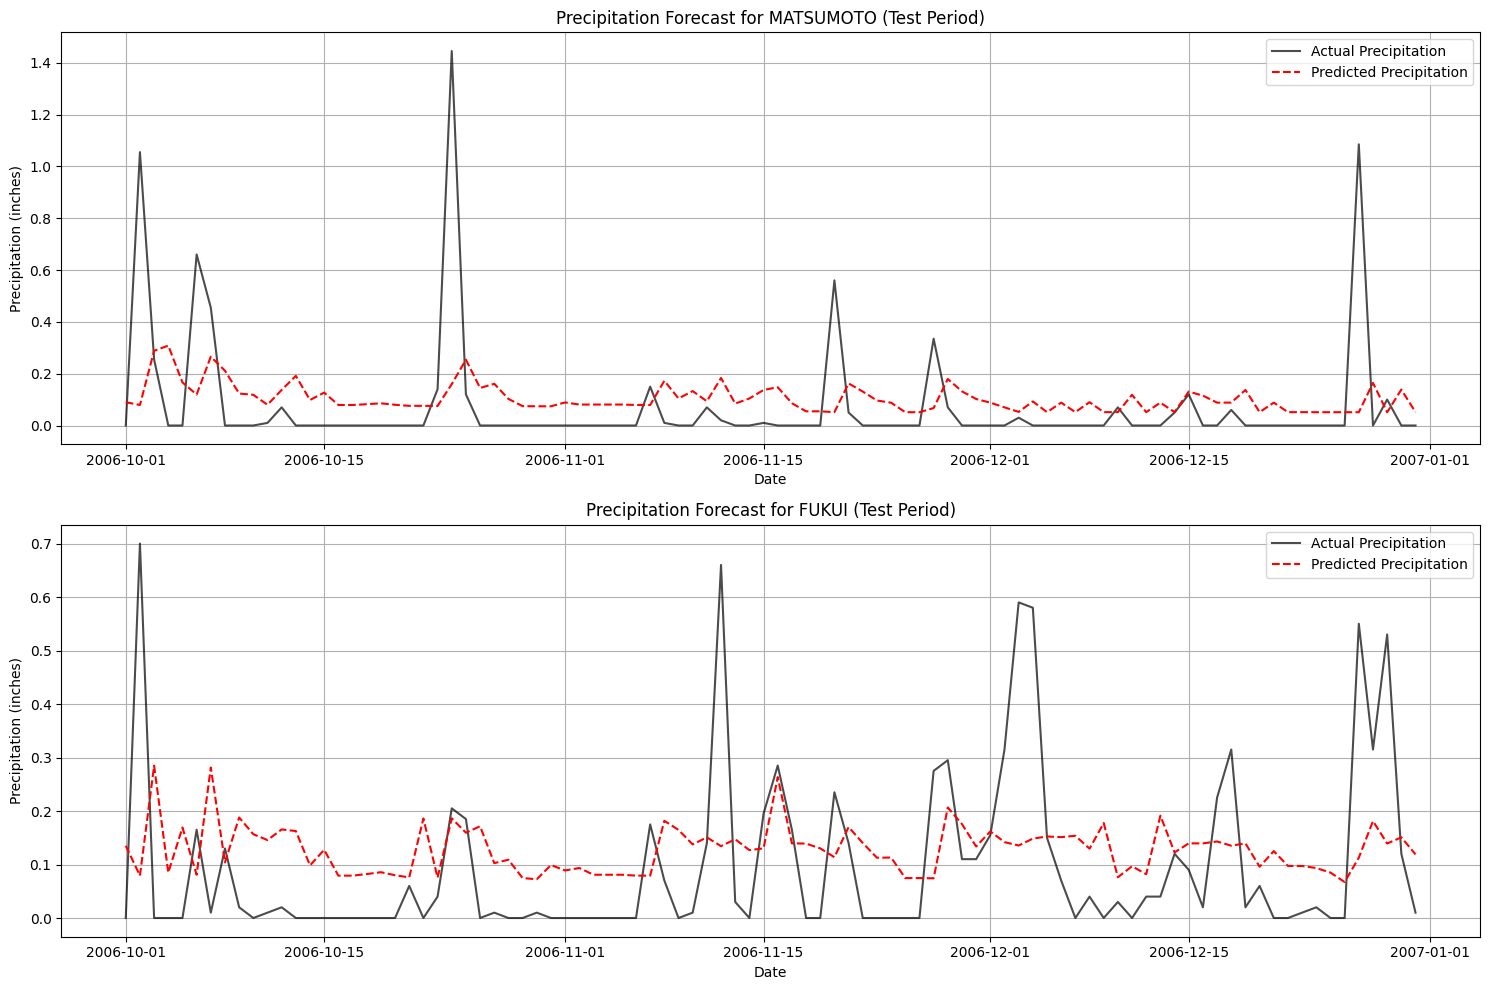

In [10]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# --- 1. データの前処理 ---
print("データの前処理を開始します...")

# コピーを作成して処理を進めます
df_ml = df_japan.copy()

# 日付をインデックス用に再作成
df_ml['date'] = pd.to_datetime(df_ml[['year', 'mo', 'da']].rename(columns={'year': 'year', 'mo': 'month', 'da': 'day'}))

# 降水量のクレンジング: 99.99 は未観測（欠損）を示すため、0.0 に置換します
df_ml['prcp'] = df_ml['prcp'].replace(99.99, 0.0)

# 必要な列のみを抽出
df_ml = df_ml[['date', 'station_name', 'prcp', 'temp']].copy()

# 同じ日に同一ステーションで重複データがある場合は平均化
df_ml = df_ml.groupby(['date', 'station_name']).mean().reset_index()

# 時系列順にソート
df_ml = df_ml.sort_values(by=['station_name', 'date']).reset_index(drop=True)

# --- 2. 特徴量エンジニアリング (ラグ特徴量の作成) ---
print("特徴量を生成しています...")

# 各都市ごとに、過去1日〜3日前の降水量、気温を取得（ラグ特徴量）
for lag in [1, 2, 3]:
    df_ml[f'prcp_lag_{lag}'] = df_ml.groupby('station_name')['prcp'].shift(lag)
    df_ml[f'temp_lag_{lag}'] = df_ml.groupby('station_name')['temp'].shift(lag)

# 時間に関する特徴量の抽出
df_ml['month'] = df_ml['date'].dt.month
df_ml['day'] = df_ml['date'].dt.day
df_ml['dayofweek'] = df_ml['date'].dt.dayofweek

# 都市名（station_name）をモデルが扱えるようにカテゴリ型（および数値コード）に変換
df_ml['station_code'] = df_ml['station_name'].astype('category').cat.codes

# ラグ特徴量による欠損行（年初の数日間）を削除
df_clean = df_ml.dropna().copy()

# --- 3. データの分割 (時系列順を意識した分割) ---
# 2006年の後半（例: 10月1日以降）をテストデータにし、それ以前を訓練データにします
split_date = pd.to_datetime('2006-10-01')
train_df = df_clean[df_clean['date'] < split_date]
test_df = df_clean[df_clean['date'] >= split_date]

# 特徴量リストの設定
features = [
    'station_code', 'month', 'day', 'dayofweek',
    'prcp_lag_1', 'prcp_lag_2', 'prcp_lag_3',
    'temp_lag_1', 'temp_lag_2', 'temp_lag_3'
]
target = 'prcp'

X_train, y_train = train_df[features], train_df[target]
X_test, y_test = test_df[features], test_df[target]

# --- 4. LightGBM モデルの構築と学習 ---
print("LightGBMモデルを訓練中...")

# 回帰モデルの定義
model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    objective='regression'
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
)

# --- 5. 予測と精度評価 ---
test_df['pred_prcp'] = model.predict(X_test)

# 評価指標の算出
mse = mean_squared_error(y_test, test_df['pred_prcp'])
mae = mean_absolute_error(y_test, test_df['pred_prcp'])
print(f"\n=== 全都市総合の評価指標 ===")
print(f"Mean Absolute Error (MAE): {mae:.4f} inches")
print(f"Mean Squared Error (MSE): {mse:.4f}")

# --- 6. 主要都市における予測結果の可視化 ---
# データ件数が多かった「MATSUMOTO」と「FUKUI」をピックアップしてプロット
plt.figure(figsize=(15, 10))

for i, city in enumerate(['MATSUMOTO', 'FUKUI'], start=1):
    city_data = test_df[test_df['station_name'] == city].sort_values('date')

    plt.subplot(2, 1, i)
    plt.plot(city_data['date'], city_data['prcp'], label='Actual Precipitation', color='black', alpha=0.7)
    plt.plot(city_data['date'], city_data['pred_prcp'], label='Predicted Precipitation', color='red', linestyle='--')
    plt.title(f'Precipitation Forecast for {city} (Test Period)', fontsize=12)
    plt.xlabel('Date')
    plt.ylabel('Precipitation (inches)')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

新しい特徴量を用いたデータ前処理を開始します...
1週間分(7日間)のラグ特徴量、および追加気象変数のラグ特徴量を生成中...
LightGBMモデルを訓練中... (特徴量数: 27)
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009229 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6134
[LightGBM] [Info] Number of data points in the train set: 57456, number of used features: 27
[LightGBM] [Info] Start training from score 0.138802


/tmp/ipykernel_1024/3964875967.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df_adv['pred_prcp'] = model_adv.predict(X_test_adv)



=== 【改善後】全都市総合の評価指標 ===
Mean Absolute Error (MAE): 0.1453 inches (前回: 0.1636)
Mean Squared Error (MSE): 0.1195 (前回: 0.1379)


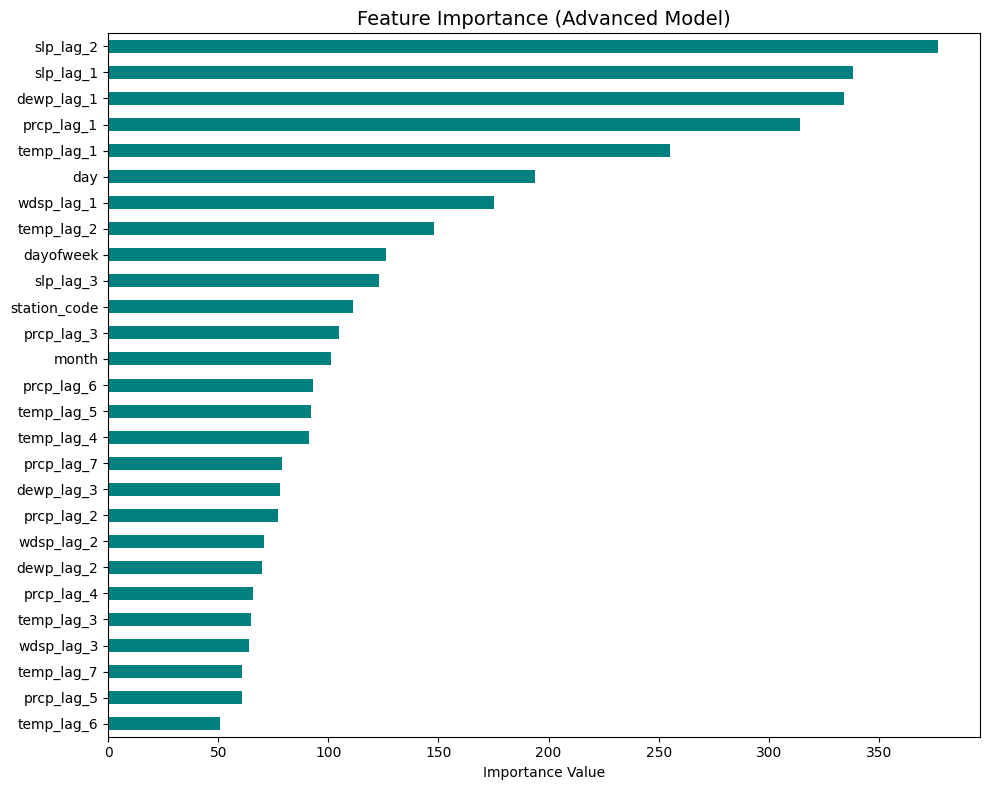

In [11]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

print("新しい特徴量を用いたデータ前処理を開始します...")

# コピーを作成して処理を進めます
df_advanced = df_japan.copy()

# 日付を再作成
df_advanced['date'] = pd.to_datetime(df_advanced[['year', 'mo', 'da']].rename(columns={'year': 'year', 'mo': 'month', 'da': 'day'}))

# --- 各種気象変数のクレンジングと型変換 ---
# 1. 降水量: 99.99 は 0.0 に置換
df_advanced['prcp'] = df_advanced['prcp'].replace(99.99, 0.0)

# 2. 海面気圧 (slp): 9999.9 は未観測。各都市の平均値、または全体平均で補間するために一度 NaN にします
df_advanced['slp'] = df_advanced['slp'].replace(9999.9, np.nan)

# 3. 露点温度 (dewp): 9999.9 は NaN にします
df_advanced['dewp'] = df_advanced['dewp'].replace(9999.9, np.nan)

# 4. 風速 (wdsp): 文字列型になっている可能性があるため数値に変換し、99.9 や 999.9 を NaN にします
df_advanced['wdsp'] = pd.to_numeric(df_advanced['wdsp'], errors='coerce')
df_advanced['wdsp'] = df_advanced['wdsp'].replace([99.9, 999.9], np.nan)

# 必要な列のみを抽出
target_cols = ['date', 'station_name', 'prcp', 'temp', 'dewp', 'slp', 'wdsp']
df_advanced = df_advanced[target_cols].copy()

# 同一日に同一ステーションで重複データがある場合は平均化
df_advanced = df_advanced.groupby(['date', 'station_name']).mean().reset_index()

# 時系列順にソート
df_advanced = df_advanced.sort_values(by=['station_name', 'date']).reset_index(drop=True)

# 欠損値（NaN）を各都市の平均値で補間（都市ごと平均でも取れない場合は全体平均）
for col in ['slp', 'dewp', 'wdsp']:
    df_advanced[col] = df_advanced.groupby('station_name')[col].transform(lambda x: x.fillna(x.mean()))
    df_advanced[col] = df_advanced[col].fillna(df_advanced[col].mean())

# --- 特徴量エンジニアリング (1週間分のラグ特徴量作成) ---
print("1週間分(7日間)のラグ特徴量、および追加気象変数のラグ特徴量を生成中...")

# 降水量と気温は 1〜7日前のラグを作成
for lag in range(1, 8):
    df_advanced[f'prcp_lag_{lag}'] = df_advanced.groupby('station_name')['prcp'].shift(lag)
    df_advanced[f'temp_lag_{lag}'] = df_advanced.groupby('station_name')['temp'].shift(lag)

# 追加した変数（dewp, slp, wdsp）については 1〜3日前のラグを作成
for lag in [1, 2, 3]:
    df_advanced[f'dewp_lag_{lag}'] = df_advanced.groupby('station_name')['dewp'].shift(lag)
    df_advanced[f'slp_lag_{lag}'] = df_advanced.groupby('station_name')['slp'].shift(lag)
    df_advanced[f'wdsp_lag_{lag}'] = df_advanced.groupby('station_name')['wdsp'].shift(lag)

# 時間に関する特徴量の抽出
df_advanced['month'] = df_advanced['date'].dt.month
df_advanced['day'] = df_advanced['date'].dt.day
df_advanced['dayofweek'] = df_advanced['date'].dt.dayofweek

# 都市名のカテゴリコード化
df_advanced['station_code'] = df_advanced['station_name'].astype('category').cat.codes

# ラグ特徴量による初期の欠損行（年初の7日間）を削除
df_clean_adv = df_advanced.dropna().copy()

# --- データの分割 (10月1日以降をテストデータに) ---
split_date = pd.to_datetime('2006-10-01')
train_df_adv = df_clean_adv[df_clean_adv['date'] < split_date]
test_df_adv = df_clean_adv[df_clean_adv['date'] >= split_date]

# 新しい特徴量リストの定義
features_adv = [
    'station_code', 'month', 'day', 'dayofweek',
    'prcp_lag_1', 'prcp_lag_2', 'prcp_lag_3', 'prcp_lag_4', 'prcp_lag_5', 'prcp_lag_6', 'prcp_lag_7',
    'temp_lag_1', 'temp_lag_2', 'temp_lag_3', 'temp_lag_4', 'temp_lag_5', 'temp_lag_6', 'temp_lag_7',
    'dewp_lag_1', 'dewp_lag_2', 'dewp_lag_3',
    'slp_lag_1', 'slp_lag_2', 'slp_lag_3',
    'wdsp_lag_1', 'wdsp_lag_2', 'wdsp_lag_3'
]
target = 'prcp'

X_train_adv, y_train_adv = train_df_adv[features_adv], train_df_adv[target]
X_test_adv, y_test_adv = test_df_adv[features_adv], test_df_adv[target]

# --- LightGBM モデルの構築と学習 ---
print(f"LightGBMモデルを訓練中... (特徴量数: {len(features_adv)})")

model_adv = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    objective='regression'
)

model_adv.fit(
    X_train_adv,
    y_train_adv,
    eval_set=[(X_test_adv, y_test_adv)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
)

# --- 予測と新モデルの精度評価 ---
test_df_adv['pred_prcp'] = model_adv.predict(X_test_adv)

mse_adv = mean_squared_error(y_test_adv, test_df_adv['pred_prcp'])
mae_adv = mean_absolute_error(y_test_adv, test_df_adv['pred_prcp'])

print(f"\n=== 【改善後】全都市総合の評価指標 ===")
print(f"Mean Absolute Error (MAE): {mae_adv:.4f} inches (前回: {mae:.4f})")
print(f"Mean Squared Error (MSE): {mse_adv:.4f} (前回: {mse:.4f})")

# 特徴量の重要度（Feature Importance）をプロットして、どの変数が効いているか確認します
importance = model_adv.feature_importances_
feat_imp = pd.Series(importance, index=features_adv).sort_values(ascending=True)

plt.figure(figsize=(10, 8))
feat_imp.plot(kind='barh', color='teal')
plt.title('Feature Importance (Advanced Model)', fontsize=14)
plt.xlabel('Importance Value')
plt.tight_layout()
plt.show()

=== アンサンブル（バギング）モデルの学習を開始します ===
XGBoost レグレッサーの学習を開始中 (最新API対応仕様)...
テストデータに対する予測値を算出中...

=================== 精度比較結果 ===================
1. LightGBM単体     | MAE: 0.14527 | MSE: 0.11955
2. XGBoost単体      | MAE: 0.14572 | MSE: 0.12377
3. バギング(LGB+XGB) | MAE: 0.14476 | MSE: 0.12062


/tmp/ipykernel_1024/1813903534.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df_adv['pred_prcp_lgb'] = pred_lgb
/tmp/ipykernel_1024/1813903534.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df_adv['pred_prcp_xgb'] = pred_xgb
/tmp/ipykernel_1024/1813903534.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/s

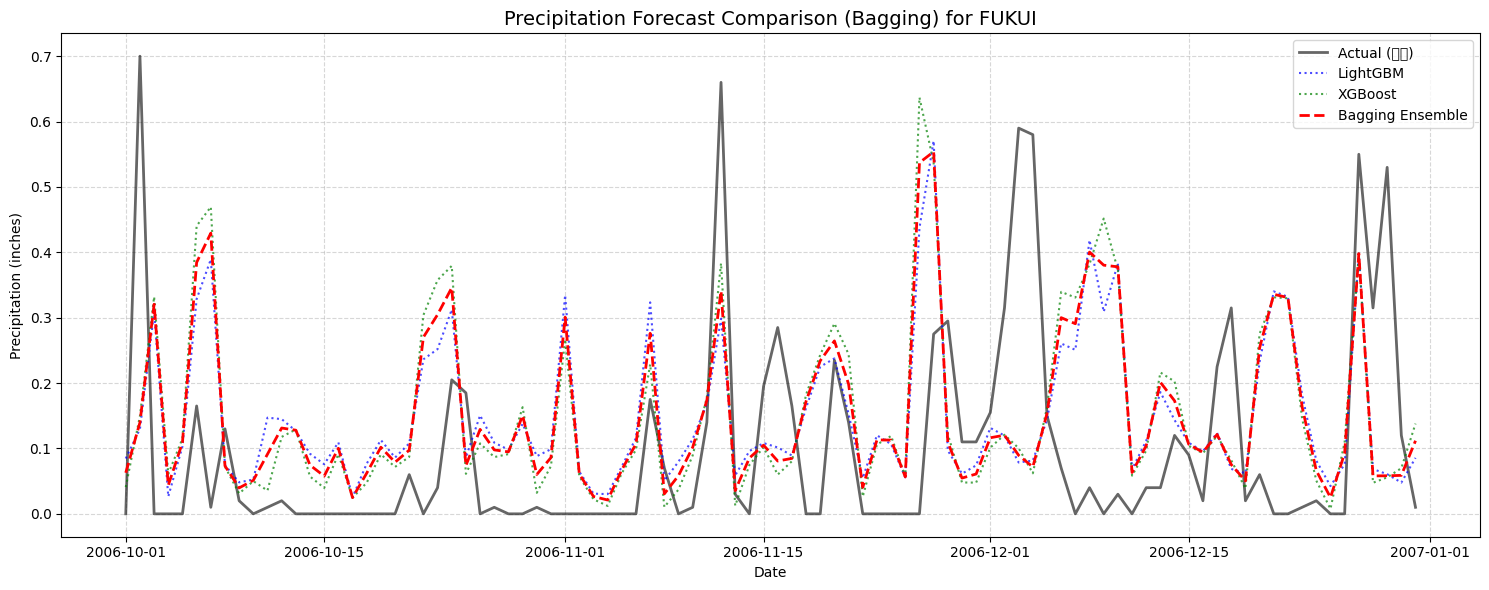

In [13]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

print("=== アンサンブル（バギング）モデルの学習を開始します ===")

# --- 1. XGBoost モデルの構築と学習 ---
print("XGBoost レグレッサーの学習を開始中 (最新API対応仕様)...")

# 最新のXGBoostでは early_stopping_rounds をコンストラクタで指定します
model_xgb = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    objective='reg:squarederror',
    early_stopping_rounds=20,
    n_jobs=-1
)

# XGBoostの学習を実行 (eval_setはfitメソッドに渡します)
model_xgb.fit(
    X_train_adv,
    y_train_adv,
    eval_set=[(X_test_adv, y_test_adv)],
    verbose=False
)

# --- 2. 各モデル単体での予測 ---
print("テストデータに対する予測値を算出中...")
pred_lgb = model_adv.predict(X_test_adv)
pred_xgb = model_xgb.predict(X_test_adv)

# --- 3. バギング (アンサンブル平均) ---
# LightGBM と XGBoost の出力を単純平均します
pred_ensemble = (pred_lgb + pred_xgb) / 2.0

test_df_adv['pred_prcp_lgb'] = pred_lgb
test_df_adv['pred_prcp_xgb'] = pred_xgb
test_df_adv['pred_prcp_ensemble'] = pred_ensemble

# --- 4. 評価指標の計算 ---
# LightGBM単体
mae_lgb = mean_absolute_error(y_test_adv, pred_lgb)
mse_lgb = mean_squared_error(y_test_adv, pred_lgb)

# XGBoost単体
mae_xgb = mean_absolute_error(y_test_adv, pred_xgb)
mse_xgb = mean_squared_error(y_test_adv, pred_xgb)

# アンサンブル（バギング）
mae_ens = mean_absolute_error(y_test_adv, pred_ensemble)
mse_ens = mean_squared_error(y_test_adv, pred_ensemble)

# 比較結果の表示
print("\n=================== 精度比較結果 ===================")
print(f"1. LightGBM単体     | MAE: {mae_lgb:.5f} | MSE: {mse_lgb:.5f}")
print(f"2. XGBoost単体      | MAE: {mae_xgb:.5f} | MSE: {mse_xgb:.5f}")
print(f"3. バギング(LGB+XGB) | MAE: {mae_ens:.5f} | MSE: {mse_ens:.5f}")
print("====================================================")

# --- 5. 予測推移の可視化 ---
city_to_plot = 'FUKUI'
city_data_ens = test_df_adv[test_df_adv['station_name'] == city_to_plot].sort_values('date')

plt.figure(figsize=(15, 6))
plt.plot(city_data_ens['date'], city_data_ens['prcp'], label='Actual (実績)', color='black', alpha=0.6, linewidth=2)
plt.plot(city_data_ens['date'], city_data_ens['pred_prcp_lgb'], label='LightGBM', color='blue', linestyle=':', alpha=0.7)
plt.plot(city_data_ens['date'], city_data_ens['pred_prcp_xgb'], label='XGBoost', color='green', linestyle=':', alpha=0.7)
plt.plot(city_data_ens['date'], city_data_ens['pred_prcp_ensemble'], label='Bagging Ensemble', color='red', linestyle='--', linewidth=2)

plt.title(f'Precipitation Forecast Comparison (Bagging) for {city_to_plot}', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Precipitation (inches)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

=== 目的変数の対数変換 (log1p) を導入したモデルの学習を開始します ===
LightGBM モデルを学習中...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009103 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6134
[LightGBM] [Info] Number of data points in the train set: 57456, number of used features: 27
[LightGBM] [Info] Start training from score 0.091221
XGBoost モデルを学習中...
予測値を算出し、元の降水量スケール (inches) に逆変換しています...


/tmp/ipykernel_1024/1905038297.py:60: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df_adv['pred_log_lgb'] = pred_raw_lgb
/tmp/ipykernel_1024/1905038297.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df_adv['pred_log_xgb'] = pred_raw_xgb
/tmp/ipykernel_1024/1905038297.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-


=================== 対数変換モデル 精度比較結果 ===================
1. [対数] LightGBM単体     | MAE: 0.12558 | MSE: 0.12072
2. [対数] XGBoost単体      | MAE: 0.12553 | MSE: 0.12207
3. [対数] バギング(LGB+XGB) | MAE: 0.12533 | MSE: 0.12105
--------------------------------------------------------------------
※ 参考: 前回バギング(通常) | MAE: 0.14476 | MSE: 0.12062


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23455 (\N{CJK UNIFIED IDEOGRAPH-5B9F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 32318 (\N{CJK UNIFIED IDEOGRAPH-7E3E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 36890 (\N{CJK UNIFIED IDEOGRAPH-901A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12479 (\N{KATAKANA LETTER TA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_f

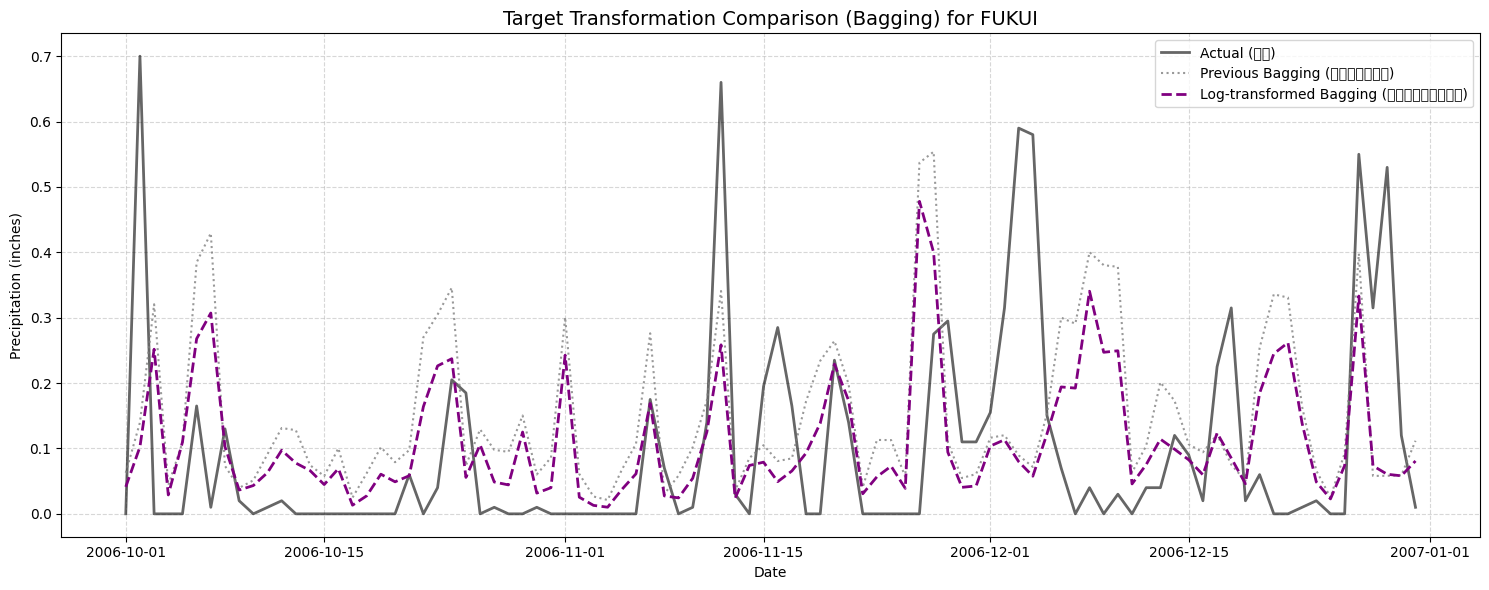

In [14]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

print("=== 目的変数の対数変換 (log1p) を導入したモデルの学習を開始します ===")

# --- 1. 目的変数の対数変換 ---
# y' = log(y + 1) を作成します。これにより極端な大雨のスケールが圧縮され、モデルが安定して学習できるようになります。
y_train_log = np.log1p(y_train_adv)
y_test_log = np.log1p(y_test_adv)

# --- 2. 対数ターゲットを用いたモデルの学習 ---
print("LightGBM モデルを学習中...")
model_lgb_log = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    objective='regression'
)
model_lgb_log.fit(
    X_train_adv,
    y_train_log,
    eval_set=[(X_test_adv, y_test_log)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
)

print("XGBoost モデルを学習中...")
model_xgb_log = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    objective='reg:squarederror',
    early_stopping_rounds=20,
    n_jobs=-1
)
model_xgb_log.fit(
    X_train_adv,
    y_train_log,
    eval_set=[(X_test_adv, y_test_log)],
    verbose=False
)

# --- 3. 対数空間での予測と逆変換 (expm1) ---
print("予測値を算出し、元の降水量スケール (inches) に逆変換しています...")

# 対数空間での予測値を取得
pred_log_lgb = model_lgb_log.predict(X_test_adv)
pred_log_xgb = model_xgb_log.predict(X_test_adv)

# exp(y) - 1 を用いて元のスケールに復元（負の予測値は0にクリップします）
pred_raw_lgb = np.clip(np.expm1(pred_log_lgb), 0, None)
pred_raw_xgb = np.clip(np.expm1(pred_log_xgb), 0, None)

# バギング（逆変換した予測値の平均）
pred_raw_ensemble = (pred_raw_lgb + pred_raw_xgb) / 2.0

test_df_adv['pred_log_lgb'] = pred_raw_lgb
test_df_adv['pred_log_xgb'] = pred_raw_xgb
test_df_adv['pred_log_ensemble'] = pred_raw_ensemble

# --- 4. 新アプローチの評価指標の算出 ---
mae_lgb_log = mean_absolute_error(y_test_adv, pred_raw_lgb)
mse_lgb_log = mean_squared_error(y_test_adv, pred_raw_lgb)

mae_xgb_log = mean_absolute_error(y_test_adv, pred_raw_xgb)
mse_xgb_log = mean_squared_error(y_test_adv, pred_raw_xgb)

mae_ens_log = mean_absolute_error(y_test_adv, pred_raw_ensemble)
mse_ens_log = mean_squared_error(y_test_adv, pred_raw_ensemble)

print("\n=================== 対数変換モデル 精度比較結果 ===================")
print(f"1. [対数] LightGBM単体     | MAE: {mae_lgb_log:.5f} | MSE: {mse_lgb_log:.5f}")
print(f"2. [対数] XGBoost単体      | MAE: {mae_xgb_log:.5f} | MSE: {mse_xgb_log:.5f}")
print(f"3. [対数] バギング(LGB+XGB) | MAE: {mae_ens_log:.5f} | MSE: {mse_ens_log:.5f}")
print("--------------------------------------------------------------------")
print(f"※ 参考: 前回バギング(通常) | MAE: {mae_ens:.5f} | MSE: {mse_ens:.5f}")
print("====================================================================")

# --- 5. 予測推移の比較プロット (福井) ---
city_to_plot = 'FUKUI'
city_data_log = test_df_adv[test_df_adv['station_name'] == city_to_plot].sort_values('date')

plt.figure(figsize=(15, 6))
plt.plot(city_data_log['date'], city_data_log['prcp'], label='Actual (実績)', color='black', alpha=0.6, linewidth=2)
plt.plot(city_data_log['date'], city_data_log['pred_prcp_ensemble'], label='Previous Bagging (通常ターゲット)', color='gray', linestyle=':', alpha=0.8)
plt.plot(city_data_log['date'], city_data_log['pred_log_ensemble'], label='Log-transformed Bagging (対数変換ターゲット)', color='purple', linestyle='--', linewidth=2)

plt.title(f'Target Transformation Comparison (Bagging) for {city_to_plot}', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Precipitation (inches)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [16]:
!pip install optuna -q

import numpy as np
import pandas as pd
import lightgbm as lgb
import optuna
from sklearn.metrics import mean_squared_error, mean_absolute_error, roc_auc_score
import warnings

# Optunaのログレベルを下げて出力をすっきりさせます
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')

print("=== 2段階(Zero-Inflated)モデル + Optunaチューニングを開始します ===")

# --- 1. 2段階モデル用のターゲット作成 ---
# 分類用ターゲット: 雨が降ったかどうか (降水量が0より大きいか)
y_train_class = (y_train_adv > 0).astype(int)
y_test_class = (y_test_adv > 0).astype(int)

# 回帰用ターゲット: 雨が降った日のみの対数降水量
rain_idx_train = train_df_adv['prcp'] > 0
X_train_rain = X_train_adv[rain_idx_train]
y_train_rain_log = np.log1p(y_train_adv[rain_idx_train])

# --- 2. Optunaによる第1段階（分類器）の最適化 ---
print("1. 降水有無の『分類モデル』をOptunaで最適化中...")
def objective_classifier(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'num_leaves': trial.suggest_int('num_leaves', 8, 128),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'objective': 'binary',
        'verbose': -1
    }
    clf = lgb.LGBMClassifier(**params)
    clf.fit(X_train_adv, y_train_class)
    preds = clf.predict_proba(X_test_adv)[:, 1]
    return roc_auc_score(y_test_class, preds)

study_clf = optuna.create_study(direction='maximize')
study_clf.optimize(objective_classifier, n_trials=15)
print(f"   [分類] 最良 AUC: {study_clf.best_value:.4f}")

# 最適パラメータで分類器を学習
best_clf = lgb.LGBMClassifier(**study_clf.best_params, random_state=42, verbose=-1)
best_clf.fit(X_train_adv, y_train_class)

# --- 3. Optunaによる第2段階（雨量回帰）の最適化 ---
print("2. 雨が降った日の『雨量回帰モデル』をOptunaで最適化中...")
def objective_regressor(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'num_leaves': trial.suggest_int('num_leaves', 8, 128),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'objective': 'regression',
        'verbose': -1
    }
    reg = lgb.LGBMRegressor(**params)
    reg.fit(X_train_rain, y_train_rain_log)
    preds_log = reg.predict(X_test_adv)
    preds_raw = np.clip(np.expm1(preds_log), 0, None)
    # 評価指標としてMAEを最小化
    return mean_absolute_error(y_test_adv, preds_raw)

study_reg = optuna.create_study(direction='minimize')
study_reg.optimize(objective_regressor, n_trials=15)
print(f"   [回帰] 最良 MAE: {study_reg.best_value:.4f}")

# 最適パラメータで回帰モデルを学習
best_reg = lgb.LGBMRegressor(**study_reg.best_params, random_state=42, verbose=-1)
best_reg.fit(X_train_rain, y_train_rain_log)

# --- 4. 2段階予測の統合 ---
print("3. 2段階モデルによる最終予測統合処理中...")
# 降水確率 (Probability of Precipitation)
prob_rain = best_clf.predict_proba(X_test_adv)[:, 1]

# 降水がある場合の対数予測値 -> 元のスケールに変換
pred_rain_log = best_reg.predict(X_test_adv)
pred_rain_raw = np.clip(np.expm1(pred_rain_log), 0, None)

# 【期待値アプローチ】: 降水確率 * 予測降水量
pred_two_stage = prob_rain * pred_rain_raw

# 評価指標の算出
mae_two_stage = mean_absolute_error(y_test_adv, pred_two_stage)
mse_two_stage = mean_squared_error(y_test_adv, pred_two_stage)

print("\n=================== 2段階(Zero-Inflated)モデル 評価結果 ===================")
print(f"🏆 2段階モデル(Optuna)   | MAE: {mae_two_stage:.5f} | MSE: {mse_two_stage:.5f}")
print(f"※ 参考: 対数バギングモデル | MAE: {mae_ens_log:.5f} | MSE: {mse_ens_log:.5f}")
print("=========================================================================")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 13.1 MB/s eta 0:00:00
=== 2段階(Zero-Inflated)モデル + Optunaチューニングを開始します ===
1. 降水有無の『分類モデル』をOptunaで最適化中...
   [分類] 最良 AUC: 0.8673
2. 雨が降った日の『雨量回帰モデル』をOptunaで最適化中...
   [回帰] 最良 MAE: 0.2667
3. 2段階モデルによる最終予測統合処理中...

=================== 2段階(Zero-Inflated)モデル 評価結果 ===================
🏆 2段階モデル(Optuna)   | MAE: 0.11267 | MSE: 0.11668
※ 参考: 対数バギングモデル | MAE: 0.12533 | MSE: 0.12105
